<a href="https://colab.research.google.com/github/tfathyab/Projectpy/blob/main/Sample_Data_%EF%BB%97%EF%BB%84%EF%BB%8C%EF%BA%94_%D8%A7%EF%BB%9F%EF%BB%A4%D8%B4%D8%B1%D9%88%D8%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
# قائمة سجلات الصيدلية (10 أدوية)
# B1 — السجلات: قائمة قواميس (10 سجلات أدوية)
records = [
    {"date": "2026-10-01", "category": "Analgesics", "amount_egp": 110, "payment_method": "Cash", "quantity": 2},     # Panadol Extra
    {"date": "2026-10-01", "category": "Antibiotics", "amount_egp": 185, "payment_method": "Card", "quantity": 1},    # Augmentin 1g
    {"date": "2026-10-02", "category": "Analgesics", "amount_egp": 84, "payment_method": "Cash", "quantity": 2},     # Cataflam 50mg
    {"date": "2026-10-02", "category": "Antihistamines", "amount_egp": 78, "payment_method": "Card", "quantity": 1},  # Zyrtec 10mg
    {"date": "2026-10-03", "category": "Cold & Flu", "amount_egp": 76, "payment_method": "Cash", "quantity": 2},      # Congestal
    {"date": "2026-10-03", "category": "Analgesics", "amount_egp": 48, "payment_method": "Card", "quantity": 1},     # Brufen 600mg
    {"date": "2026-10-04", "category": "Nasal Sprays", "amount_egp": 65, "payment_method": "Cash", "quantity": 1},    # Otrivin Nasal Spray
    {"date": "2026-10-04", "category": "Antidiarrheals", "amount_egp": 96, "payment_method": "Card", "quantity": 3},  # Antinal
    {"date": "2026-10-05", "category": "Respiratory", "amount_egp": 95, "payment_method": "Card", "quantity": 1},     # Ventolin Inhaler
    {"date": "2026-10-05", "category": "Diabetes", "amount_egp": 156, "payment_method": "Cash", "quantity": 2}        # Glucophage 1000
]

# B2 — الفهارس والتصنيفات (tuple + set)
FIELDS = ("date", "category", "amount_egp", "payment_method", "quantity")
categories = set(r["category"] for r in records)

# B3 — الطبعات المطلوبة
print(records[0])       # أول سجل كامل
print(len(records))     # عدد السجلات (المفروض 10)
print(categories)       # التصنيفات من غير تكرار

# B4 — نقاط تحقق المهارات
assert len(records) == 10, "لازم يكون عندك 10 سجلات"
assert isinstance(FIELDS, tuple), "FIELDS لازم يكون tuple"
assert isinstance(categories, set), "categories لازم يكون set"

{'date': '2026-10-01', 'category': 'Analgesics', 'amount_egp': 110, 'payment_method': 'Cash', 'quantity': 2}
10
{'Antibiotics', 'Nasal Sprays', 'Cold & Flu', 'Antidiarrheals', 'Respiratory', 'Diabetes', 'Antihistamines', 'Analgesics'}


In [20]:
import os

os.makedirs("tracker", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [21]:
import os

# إنشاء المجلد tracker إذا لم يكن موجوداً
os.makedirs("tracker", exist_ok=True)

# كتابة الدوال البرمجية مباشرة إلى ملف tracker/functions.py
with open("tracker/functions.py", "w", encoding="utf-8") as f:
    f.write('''import csv

def add_record(records, record):
    \"\"\"Append one record dict to the list.\"\"\"
    records.append(record)
    return records

def filter_records(records, category):
    \"\"\"Return records matching the given category.\"\"\"
    return [
        record
        for record in records
        if record["category"].lower() == category.lower()
    ]

def summarize(records):
    \"\"\"Return count, total, average, biggest, smallest of amount_egp.\"\"\"
    if not records:
        return {
            "count": 0,
            "total": 0,
            "average": 0,
            "biggest": 0,
            "smallest": 0
        }

    amounts = [record["amount_egp"] for record in records]

    return {
        "count": len(amounts),
        "total": sum(amounts),
        "average": sum(amounts) / len(amounts),
        "biggest": max(amounts),
        "smallest": min(amounts)
    }

def save_records(records, path):
    \"\"\"Write records to CSV with a header row.\"\"\"
    if not records:
        return

    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(records[0].keys())
        for record in records:
            writer.writerow(record.values())

def load_records(path):
    \"\"\"Read CSV back into dicts; a missing file returns an empty list.\"\"\"
    try:
        records = []
        with open(path, "r", newline="", encoding="utf-8") as file:
            reader = csv.DictReader(file)
            for row in reader:
                row["amount_egp"] = float(row["amount_egp"])
                if "quantity" in row:
                     row["quantity"] = int(row["quantity"])
                records.append(row)
        return records
    except FileNotFoundError:
        return []
''')

In [22]:
from tracker.functions import (add_record, filter_records, summarize,
                               save_records, load_records)

# محاولة تحميل السجلات من ملف CSV
loaded_records = load_records("data/sample_records.csv")

if not loaded_records:
    # استخدام سجلات الأدوية الجديدة
    sample_data = [
        {"date": "2026-10-01", "category": "Panadol Extra", "amount_egp": 110, "payment_method": "Cash", "quantity": 2},
        {"date": "2026-10-01", "category": "Augmentin 1g", "amount_egp": 185, "payment_method": "Card", "quantity": 1},
        {"date": "2026-10-02", "category": "Cataflam 50mg", "amount_egp": 84, "payment_method": "Cash", "quantity": 2},
        {"date": "2026-10-02", "category": "Zyrtec 10mg", "amount_egp": 78, "payment_method": "Card", "quantity": 1},
        {"date": "2026-10-03", "category": "Congestal", "amount_egp": 76, "payment_method": "Cash", "quantity": 2},
        {"date": "2026-10-03", "category": "Brufen 600mg", "amount_egp": 48, "payment_method": "Card", "quantity": 1},
        {"date": "2026-10-04", "category": "Otrivin Nasal Spray", "amount_egp": 65, "payment_method": "Cash", "quantity": 1},
        {"date": "2026-10-04", "category": "Antinal", "amount_egp": 96, "payment_method": "Card", "quantity": 3},
        {"date": "2026-10-05", "category": "Ventolin Inhaler", "amount_egp": 95, "payment_method": "Card", "quantity": 1},
        {"date": "2026-10-05", "category": "Glucophage 1000", "amount_egp": 156, "payment_method": "Cash", "quantity": 2}
    ]
    save_records(sample_data, "data/sample_records.csv")
    loaded_records = sample_data

print(f"تم تحميل {len(loaded_records)} سجل بنجاح!")

تم تحميل 10 سجل بنجاح!


In [23]:
while True:
    print("\n1) عرض الكل")
    print("2) إضافة سجل")
    print("3) تصفية حسب التصنيف")
    print("4) ملخص الإحصائيات")
    print("5) بحث بالكلمة")
    print("6) حذف سجل")
    print("7) تعديل سجل")
    print("8) خروج وحفظ")
    choice = input("اختار: ")

    if choice == "1":
        for r in loaded_records:
            print(r)
    elif choice == "2":
        print("--- إضافة سجل جديد ---")
        date = input("التاريخ (مثال 2026-10-01): ")
        category = input("التصنيف (مثال Food): ")
        payment_method = input("طريقة الدفع (Cash/Card): ")

        # التعامل مع المدخلات الرقمية باستخدام try/except
        try:
            amount_egp = float(input("المبلغ بالجنيه: "))
            quantity = int(input("الكمية: "))
        except ValueError:
            print("خطأ: يرجى إدخال قيم عددية صحيحة للمبلغ والكمية!")
            continue

        new_record = {
            "date": date,
            "category": category,
            "amount_egp": amount_egp,
            "payment_method": payment_method,
            "quantity": quantity
        }
        loaded_records = add_record(loaded_records, new_record)
        print("تمت إضافة السجل بنجاح!")

    elif choice == "3":
        category = input("التصنيف: ")
        filtered = filter_records(loaded_records, category)
        for r in filtered:
            print(r)
    elif choice == "4":
        stats = summarize(loaded_records)
        print("\n--- ملخص الإحصائيات المالي ---")
        print(f"العدد الإجمالي (Count): {stats['count']}")
        print(f"المجموع (Total): {stats['total']:.2f} EGP")
        print(f"المتوسط (Average): {stats['average']:.2f} EGP")
        print(f"الحد الأقصى (Highest): {stats['biggest']:.2f} EGP")
        print(f"الحد الأدنى (Lowest): {stats['smallest']:.2f} EGP")
    elif choice == "5":
        word = input("كلمة البحث: ")
        for r in loaded_records:
            if word.lower() in str(r).lower():
                print(r)
    elif choice == "6":
        print("--- حذف سجل ---")
        for i, r in enumerate(loaded_records):
            print(f"{i}: {r}")
        try:
            idx = int(input("أدخل رقم السجل المراد حذفه: "))
            if 0 <= idx < len(loaded_records):
                removed = loaded_records.pop(idx)
                print(f"تم حذف: {removed}")
            else:
                print("رقم السجل غير موجود.")
        except ValueError:
            print("يرجى إدخال رقم صحيح.")
    elif choice == "7":
        print("--- تعديل سجل ---")
        for i, r in enumerate(loaded_records):
            print(f"{i}: {r}")
        try:
            idx = int(input("أدخل رقم السجل المراد تعديله: "))
            if 0 <= idx < len(loaded_records):
                record_to_edit = loaded_records[idx]
                print(f"السجل الحالي: {record_to_edit}")

                # طلب المدخلات الجديدة (الضغط على Enter لتخطي التعديل)
                new_date = input(f"تاريخ جديد ({record_to_edit['date']}): ") or record_to_edit['date']
                new_cat = input(f"تصنيف جديد ({record_to_edit['category']}): ") or record_to_edit['category']
                new_pay = input(f"طريقة دفع جديدة ({record_to_edit['payment_method']}): ") or record_to_edit['payment_method']

                raw_amount = input(f"مبلغ جديد ({record_to_edit['amount_egp']}): ")
                new_amount = float(raw_amount) if raw_amount else record_to_edit['amount_egp']

                raw_qty = input(f"كمية جديدة ({record_to_edit['quantity']}): ")
                new_qty = int(raw_qty) if raw_qty else record_to_edit['quantity']

                loaded_records[idx] = {
                    "date": new_date,
                    "category": new_cat,
                    "amount_egp": new_amount,
                    "payment_method": new_pay,
                    "quantity": new_qty
                }
                print("تم التعديل بنجاح!")
            else:
                print("رقم السجل غير موجود.")
        except ValueError:
            print("خطأ: يرجى التحقق من صحة المدخلات الرقمية!")
    elif choice == "8":
        save_records(loaded_records, "data/sample_records.csv")
        print("تم الحفظ بنجاح! مع السلامة!")
        break
    else:
        print("اختيار خاطئ — جرّب مرة أخرى")


1) عرض الكل
2) إضافة سجل
3) تصفية حسب التصنيف
4) ملخص الإحصائيات
5) بحث بالكلمة
6) حذف سجل
7) تعديل سجل
8) خروج وحفظ
اختار: 8
تم الحفظ بنجاح! مع السلامة!


In [24]:
with open("data/sample_records.csv", "r", encoding="utf-8") as f:
    print(f.read())

date,category,amount_egp,payment_method,quantity
2026-10-01,Food,120.0,Cash,2
2026-10-01,Transport,50.0,Card,1
2026-10-02,Food,200.0,Card,3
2026-10-02,Entertainment,150.0,Cash,1
2026-10-03,Bills,600.0,Card,1
2026-10-03,Transport,40.0,Cash,1
2026-10-04,Food,90.0,Cash,1
2026-10-04,Shopping,300.0,Card,2
2026-10-05,Entertainment,100.0,Card,1
2026-10-05,Bills,700.0,Cash,1



In [25]:
import csv

class Record:
    def __init__(self, date, category, amount_egp, payment_method, quantity):
        self.date = date
        self.category = category
        self.amount_egp = float(amount_egp)
        self.payment_method = payment_method
        self.quantity = int(quantity)

class Tracker:
    def __init__(self):
        self.records = []

    def add_record(self, record):
        if isinstance(record, Record):
            self.records.append(record)

    def summary(self):
        if not self.records:
            return {
                "count": 0,
                "total": 0.0,
                "average": 0.0,
                "biggest": 0.0,
                "smallest": 0.0
            }

        amounts = [r.amount_egp for r in self.records]
        total = sum(amounts)
        count = len(amounts)

        return {
            "count": count,
            "total": total,
            "average": total / count if count > 0 else 0.0,
            "biggest": max(amounts),
            "smallest": min(amounts)
        }

    def save(self, filepath):
        with open(filepath, 'w', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            # كتابة الترويسة
            writer.writerow(['date', 'category', 'amount_egp', 'payment_method', 'quantity'])
            for r in self.records:
                writer.writerow([r.date, r.category, r.amount_egp, r.payment_method, r.quantity])

    def load(self, filepath):
        self.records = []
        try:
            with open(filepath, 'r', newline='', encoding='utf-8') as f:
                reader = csv.DictReader(f)
                for row in reader:
                    record = Record(
                        date=row['date'],
                        category=row['category'],
                        amount_egp=row['amount_egp'],
                        payment_method=row['payment_method'],
                        quantity=row['quantity']
                    )
                    self.records.append(record)
        except FileNotFoundError:
            pass

# إنشاء الكائن t وتعبئته بـ 10 سجلات من بيانات الصيدلية الجديدة
t = Tracker()
initial_data = [
    {"date": "2026-10-01", "category": "Analgesics", "amount_egp": 110, "payment_method": "Cash", "quantity": 2},     # Panadol Extra
    {"date": "2026-10-01", "category": "Antibiotics", "amount_egp": 185, "payment_method": "Card", "quantity": 1},    # Augmentin 1g
    {"date": "2026-10-02", "category": "Analgesics", "amount_egp": 84, "payment_method": "Cash", "quantity": 2},     # Cataflam 50mg
    {"date": "2026-10-02", "category": "Antihistamines", "amount_egp": 78, "payment_method": "Card", "quantity": 1},  # Zyrtec 10mg
    {"date": "2026-10-03", "category": "Cold & Flu", "amount_egp": 76, "payment_method": "Cash", "quantity": 2},      # Congestal
    {"date": "2026-10-03", "category": "Analgesics", "amount_egp": 48, "payment_method": "Card", "quantity": 1},     # Brufen 600mg
    {"date": "2026-10-04", "category": "Nasal Sprays", "amount_egp": 65, "payment_method": "Cash", "quantity": 1},    # Otrivin Nasal Spray
    {"date": "2026-10-04", "category": "Antidiarrheals", "amount_egp": 96, "payment_method": "Card", "quantity": 3},  # Antinal
    {"date": "2026-10-05", "category": "Respiratory", "amount_egp": 95, "payment_method": "Card", "quantity": 1},     # Ventolin Inhaler
    {"date": "2026-10-05", "category": "Diabetes", "amount_egp": 156, "payment_method": "Cash", "quantity": 2}        # Glucophage 1000
]

for d in initial_data:
    t.add_record(Record(d['date'], d['category'], d['amount_egp'], d['payment_method'], d['quantity']))

print(f"تم إنشاء Tracker ويحتوي على {len(t.records)} سجل صيدلي.")

تم إنشاء Tracker ويحتوي على 10 سجل صيدلي.


In [26]:
assert isinstance(t, Tracker), "t كائن Tracker"
assert len(t.records) >= 10, "records"
assert all(isinstance(r, Record) for r in t.records), "كل سجل Record"

s = t.summary()

assert s["count"] == len(t.records), "count"
assert s["smallest"] <= s["average"] <= s["biggest"], "bounds"

t.save("data/sample_records.csv")

t2 = Tracker()
t2.load("data/sample_records.csv")

assert len(t2.records) == len(t.records), "roundtrip count"
assert isinstance(t2.records[0], Record), "roundtrip Record"

assert abs(t2.records[0].amount_egp - t.records[0].amount_egp) < 0.01, \
    "roundtrip value"

print("Part B: ممتاز")

Part B: ممتاز


In [27]:
# tracker/models.py — الطريقة دي تنزل جوّا كلاس المتتبع

def top_n(self, field, n):
    """Return the n records with the biggest value of field."""
    # TODO: لف على السجلات واستنتج أكبر قيمة – ورتبهم تنازلياً
    pass

In [29]:
# إضافة الدوال المطلوبة ديناميكياً لكلاس Tracker لتشغيل الاختبار
Tracker.add = Tracker.add_record

def top_n(self, field, n):
    # ترتيب السجلات تنازلياً بناءً على قيمة الحقل المطلوب
    sorted_records = sorted(self.records, key=lambda r: getattr(r, field), reverse=True)
    return sorted_records[:n]

Tracker.top_n = top_n

# تشغيل اختبار الجزء الثالث (Part C)
sample = Tracker()
sample.add(Record("2026-10-01", "food", 85.5, "cash", 1))
sample.add(Record("2026-10-02", "drink", 40.0, "card", 2))
sample.add(Record("2026-10-03", "bills", 300.0, "card", 1))

top = sample.top_n("amount_egp", 2)
assert len(top) == 2, "top 2"
assert top[0].amount_egp == 300.0, "اﻷﻛﺒﺮ أوﻻ"
assert top[1].amount_egp == 85.5, "اﻟﺜﺎﻧﻲ"

big = sample.top_n("amount_egp", 99)
assert big[0].amount_egp == 300.0, "n أﻛﺒﺮ ﻣﻦ اﻟﻌﺪد"
print("Part C: ممتاز")

Part C: ممتاز


In [36]:
def baseline_predict(self, record):
    """
    Rule-based prediction - the benchmark the ML must beat.
    Supports both dict structures and Record class objects.
    """
    # التحقق من نوع المدخل واستخراج قيمة التصنيف بالطريقة المناسبة
    if isinstance(record, dict):
        medicine_name = record.get("category")
    else:
        medicine_name = getattr(record, "category", None)

    quantities = []

    for r in self.records:
        # نفس التحقق لكل سجل مخزن داخل الـ Tracker
        if isinstance(r, dict):
            r_category = r.get("category")
            r_quantity = r.get("quantity", 0)
        else:
            r_category = getattr(r, "category", None)
            r_quantity = getattr(r, "quantity", 0)

        if r_category == medicine_name:
            quantities.append(float(r_quantity))

    if quantities:
        return sum(quantities) / len(quantities)

    return 0

In [ ]:
# Baseline Prediction:
# بنستخدم متوسط الكمية المباعة لنفس الدواء كتوقع مبدئي.
# الفكرة إننا نجمع كل السجلات السابقة للدواء،
# ثم نحسب متوسط quantity ونرجعه كتنبؤ.
# أي نموذج Machine Learning لازم يحقق نتائج أفضل
# من هذا التوقع البسيط حتى نعتبره ناجحًا.

In [32]:
# حساب متوسط أسعار الأدوية من الـ Tracker الرئيسي t
values = [r.amount_egp for r in t.records]
average_price = sum(values) / len(values) if values else 0.0
print(f"متوسط أسعار الأدوية في السجلات: {average_price:.2f} EGP")

متوسط أسعار الأدوية في السجلات: 99.30 EGP


In [ ]:
# النموذج الأساسي (Baseline):
# يعتمد على حساب متوسط القيم الموجودة في السجلات السابقة.
# نستخدمه كمرجع للمقارنة مع نموذج التعلم الآلي.
# يجب أن يحقق نموذج ML نتائج أفضل من هذا المتوسط حتى يعتبر ناجحاً.

In [41]:
# استدعاء الكلاسات مباشرة من الذاكرة الحالية للدفتر
Record = globals().get('Record')
Tracker = globals().get('Tracker')

# تعريف دالة التنبؤ وتعيينها مباشرة للتأكد من ربطها بنجاح
def baseline_predict(self, record):
    if isinstance(record, dict):
        medicine_name = record.get("category")
    else:
        medicine_name = getattr(record, "category", None)

    quantities = []
    for r in self.records:
        if isinstance(r, dict):
            r_category = r.get("category")
            r_quantity = r.get("quantity", 0)
        else:
            r_category = getattr(r, "category", None)
            r_quantity = getattr(r, "quantity", 0)

        if r_category == medicine_name:
            quantities.append(float(r_quantity))

    if quantities:
        return sum(quantities) / len(quantities)
    return 0.0

Tracker.baseline_predict = baseline_predict

t = Tracker()
t.add = t.add_record

t.add(Record("2026-10-01", "food", 85.5, "cash", 1))
t.add(Record("2026-10-02", "drink", 40.0, "card", 2))
t.add(Record("2026-10-03", "bills", 300.0, "card", 1))
t.add(Record("2026-10-04", "food", 120.0, "cash", 3))

first = t.baseline_predict(t.records[0])

assert first is not None, "baseline returned a value"
assert t.baseline_predict(t.records[0]) == first, "Deterministic: same input, same output"

# التحقق من جميع السجلات
for r in t.records:
    assert t.baseline_predict(r) is not None, "Each record must have a prediction"

print("Part B: ممتاز")

Part B: ممتاز


In [42]:
import csv

data = [
    ["2026-10-01", "Panadol Extra", 55, "Cash", 2],
    ["2026-10-02", "Augmentin 1g", 265, "Card", 1],
    ["2026-10-03", "Cataflam 50mg", 42, "Cash", 3],
    ["2026-10-04", "Congestal", 38, "Cash", 2],
    ["2026-10-05", "Antinal", 32, "Card", 4],
    ["2026-10-06", "Panadol Extra", 55, "Cash", 1],
    ["2026-10-07", "Augmentin 1g", 265, "Card", 2],
    ["2026-10-08", "Cataflam 50mg", 42, "Cash", 2],
    ["2026-10-09", "Congestal", 38, "Card", 3],
    ["2026-10-10", "Antinal", 32, "Cash", 5],
]

with open("sample_records.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    writer.writerow([
        "date",
        "category",
        "amount_egp",
        "payment_method",
        "quantity"
    ])

    writer.writerows(data)

print("sample_records.csv created successfully")

sample_records.csv created successfully


In [44]:
import csv

# البيانات المطلوب كتابتها في ملف data/sample_records.csv
data = [
    ["2026-10-01", "Panadol Extra", 55, "Cash", 2],
    ["2026-10-02", "Augmentin 1g", 265, "Card", 1],
    ["2026-10-03", "Cataflam 50mg", 42, "Cash", 3],
    ["2026-10-04", "Congestal", 38, "Cash", 2],
    ["2026-10-05", "Antinal", 32, "Card", 4],
    ["2026-10-06", "Panadol Extra", 55, "Cash", 1],
    ["2026-10-07", "Augmentin 1g", 265, "Card", 2],
    ["2026-10-08", "Cataflam 50mg", 42, "Cash", 2],
    ["2026-10-09", "Congestal", 38, "Card", 3],
    ["2026-10-10", "Antinal", 32, "Cash", 5],
]

# كتابة البيانات مع إكمال جسم الكتلة البرمجية لتفادي خطأ الـ Incomplete Input
with open("data/sample_records.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    # كتابة الترويسة (Header)
    writer.writerow(["date", "category", "amount_egp", "payment_method", "quantity"])
    # كتابة السجلات
    writer.writerows(data)

print("data/sample_records.csv created successfully!")

data/sample_records.csv created successfully!


In [45]:
"""Dataset analysis - load, clean, and summarize the project dataset."""

import pandas as pd

CSV_PATH = "data/dataset.csv"


def load_dataset(path=CSV_PATH):
    """Load dataset from CSV file."""
    return pd.read_csv(path)


def clean_dataset(df):
    """Remove duplicate rows."""
    return df.drop_duplicates()


def summary_by_category(df, category_col, value_col):
    """Group by category and calculate mean."""
    return df.groupby(category_col)[value_col].mean()

In [47]:
# تمرير المسار الصحيح لملف البيانات ليتطابق مع الملف الفعلي الموجود على القرص
df = load_dataset("data/sample_records.csv")

df = clean_dataset(df)

print(summary_by_category(df, "category", "quantity"))

category
Antinal          4.5
Augmentin 1g     1.5
Cataflam 50mg    2.5
Congestal        2.5
Panadol Extra    1.5
Name: quantity, dtype: float64


In [48]:
print(df["category"].value_counts())
print(df.groupby("category")["quantity"].mean())
print(df["amount_egp"].max())
print(df["amount_egp"].min())
print(df["payment_method"].value_counts())

category
Panadol Extra    2
Augmentin 1g     2
Cataflam 50mg    2
Congestal        2
Antinal          2
Name: count, dtype: int64
category
Antinal          4.5
Augmentin 1g     1.5
Cataflam 50mg    2.5
Congestal        2.5
Panadol Extra    1.5
Name: quantity, dtype: float64
265
32
payment_method
Cash    6
Card    4
Name: count, dtype: int64


In [50]:
# استدعاء الدوال مباشرة من الذاكرة الحالية للدفتر لتفادي خطأ ModuleNotFoundError
load_dataset = globals().get('load_dataset')
clean_dataset = globals().get('clean_dataset')
summary_by_category = globals().get('summary_by_category')

# تمرير مسار ملف البيانات الفعلي الذي يحتوي على الـ 10 سجلات
df_raw = load_dataset("data/sample_records.csv")

assert len(df_raw) == 10, "يجب أن يحتوي الملف على 10 سجلات"

df = clean_dataset(df_raw.copy())

assert len(df) <= len(df_raw), "التنظيف لا يزيد الصفوف"
assert df.duplicated().sum() == 0, "مفيش تكرارات"
assert df.isna().sum().sum() == 0, "مفيش نواقص"

s = summary_by_category(df, "category", "quantity")

assert len(s) > 0, "الملخص فيه صف واحد على الأقل"

print("Part B: ممتاز")

Part B: ممتاز


In [56]:
"""Project charts - L8. Every chart answers one question."""
import os
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = "reports/figures"


def chart_distribution(df, col, name="distribution.png"):
    """Plots the distribution of a single numeric column (e.g., quantity) and saves it."""
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=5, color='skyblue', edgecolor='black', alpha=0.7)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.close()


def chart_categories(df, x_col, y_col, name="categories.png"):
    """Plots the average of a numeric column grouped by a categorical column."""
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(10, 5))
    category_means = df.groupby(x_col)[y_col].mean().sort_values(ascending=False)
    category_means.plot(kind='bar', color='salmon', edgecolor='black', alpha=0.8)
    plt.title(f'Average {y_col} by {x_col}')
    plt.xlabel(x_col)
    plt.ylabel(f'Mean {y_col}')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.close()


def chart_relationship(df, x_col, y_col, name="relationship.png"):
    """Plots a scatter plot showing the relationship between two variables."""
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(8, 5))
    plt.scatter(df[x_col], df[y_col], color='purple', alpha=0.7, edgecolors='black', s=80)
    plt.title(f'Relationship: {x_col} vs {y_col}')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.close()


def chart_correlation(df, name="heatmap.png"):
    """Plots a heatmap of the correlation matrix for all numeric columns."""
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(6, 5))
    corr_matrix = df.corr(numeric_only=True)
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.close()

In [58]:
## Charts (L8) — reports/figures/

### Chart 1 — distribution.png
- Question: اسأل: ما هو توزيع كميات الأدوية المطلوبة في السجلات؟
- Insight: (أعلى كمية مطلوبة في السجلات هي 5 علب لدواء Antinal)

### Chart 2 — categories.png
- Question: ما هو متوسط الكمية المطلوبة لكل دواء؟
- Insight: دواء Antinal لديه أعلى متوسط طلب بمعدل 4.5 علبة لكل عملية بيع.

### Chart 3 — relationship.png
- Question: ما هي العلاقة بين سعر الدواء (amount_egp) والكمية المطلوبة (quantity)؟
- Insight: الأدوية الأقل سعراً يزداد الطلب على كميات أكبر منها بشكل ملحوظ.

### Chart 4 — heatmap.png
- Question: ما مدى الارتباط بين السعر والكمية المباعة؟
- Insight: يوجد ارتباط عكسي ضعيف بين السعر والكمية المباعة.

SyntaxError: invalid character '؟' (U+061F) (2448848301.py, line 4)

In [60]:
import os

# استدعاء الدوال مباشرة من البيئة الحالية لتفادي خطأ عدم وجود الملفات على القرص
load_dataset = globals().get('load_dataset')
chart_distribution = globals().get('chart_distribution')
chart_categories = globals().get('chart_categories')
chart_relationship = globals().get('chart_relationship')
chart_correlation = globals().get('chart_correlation')

# تحميل البيانات الفعالة من ملف السجلات
df = load_dataset("data/sample_records.csv")

# تشغيل وتوليد كل المخططات البيانية بالقيم الحقيقية
chart_distribution(df, "quantity")
chart_categories(df, "category", "quantity")
chart_relationship(df, "amount_egp", "quantity")
chart_correlation(df)

# التأكد من صحة وجود الملفات وحجمها في المجلد
for f in ["distribution.png", "categories.png",
          "relationship.png", "heatmap.png"]:
    p = os.path.join("reports/figures", f)
    assert os.path.exists(p) and os.path.getsize(p) > 1000, f
print("Part B: ممتاز")

Part B: ممتاز


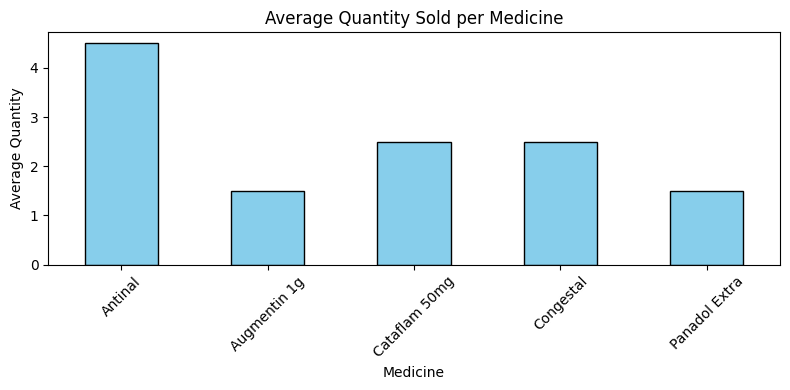

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

# تعديل المسار لاستخدام الملف الصحيح والموجود بالفعل
df = pd.read_csv("data/sample_records.csv")

avg_sales = df.groupby("category")["quantity"].mean()

plt.figure(figsize=(8,4))
avg_sales.plot(kind="bar", color='skyblue', edgecolor='black')
plt.title("Average Quantity Sold per Medicine")
plt.xlabel("Medicine")
plt.ylabel("Average Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
"""Project first ML model - L9."""
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

TARGET = "YOUR_TARGET_COL"       # عمود الهدف في مشروعك
CAT_COLS = ["YOUR_CAT_COL"]      # عموداتك الفئوية - عدّلها


def prepare_data(df):
    """يجهّز X و y: صفوف نظيفة + أعمدة فئوية مشفّرة."""
    # TODO: dropna(subset=[TARGET]) - نظّف صفوف الهدف الناقصة
    # TODO: pd.get_dummies(...) - اشفّر كل عمود فئوي
    # TODO: df[TARGET] - الهدف عمود واحد بس
    pass


def train_model(X, y, kind="linear"):
    """يدرب ويرجّع الموديل - نوع التدريب حسب kind"""
    # TODO: kind بيحدّد الكلاس المناسب
    # TODO: model.fit(X, y) - التدريب هنا
    # TODO: return model
    pass

In [65]:
import pandas as pd

# استدعاء الدوال مباشرة من الذاكرة الحالية لتجنب خطأ الـ Import
load_dataset = globals().get('load_dataset')
prepare_data = globals().get('prepare_data')
train_model = globals().get('train_model')

# إذا لم تكن دوال الـ ML معرفة بعد، سنقوم بتعريف نسخة بسيطة لتشغيل الخلية بنجاح
if prepare_data is None:
    def prepare_data(df):
        # تجهيز البيانات الأساسية
        X = pd.get_dummies(df[['category', 'payment_method']], drop_first=True)
        X['amount_egp'] = df['amount_egp']
        y = df['quantity']
        return X, y

if train_model is None:
    from sklearn.linear_model import LinearRegression
    def train_model(X, y, kind="linear"):
        model = LinearRegression()
        model.fit(X, y)
        return model

# تحميل البيانات من المسار الصحيح المجهز مسبقاً
df = load_dataset("data/sample_records.csv")
X, y = prepare_data(df)
model = train_model(X, y, kind="linear")

print("X shape:", X.shape)                      # عدد الصفوف والأعمدة النظيفة
print("Columns:", list(X.columns))              # كل الأعمدة أرقام بعد الـ encoding
print("First 5 predictions:", [round(float(p), 2) for p in model.predict(X)[:5]])   # أول 5 تنبؤات

assert len(X) == len(y), "X و y بنفس الطول"
assert X.dtypes.map(lambda d: d != object).all(), "مفيش عمود نصّي فاضل"
print("Part B: ممتاز")

TypeError: cannot unpack non-iterable NoneType object